# TP 1 — Règles d'association : le panier de la ménagère
**Module** : Machine Learning · Algorithmes  |  **Durée** : 3 h  |  **Travail** : en binôme
**Étudiants** : *(noms du binôme)*  |  **Date** : *(à remplir)*

---
##  Contexte et objectif du TP
On dispose d'**un mois de tickets de caisse** d'un supermarché (jeu **Groceries**, Hahsler 2006 : **9 835 tickets**, environ
170 catégories de produits). Il n'y a **aucune variable à prédire** : c'est de l'**apprentissage non supervisé**. On cherche
simplement **quels produits sont achetés ensemble**, sous forme de **règles** du type *« ceux qui achètent du yaourt achètent
souvent du lait entier »*, puis on en tire une **petite recommandation** utile au magasin.

Ce TP a pour but de :
1. comprendre le **format « panier »** (transactions) et le transformer en tableau exploitable ;
2. trouver les **motifs fréquents** avec l'algorithme **Apriori** (mesure : le **support**) ;
3. générer des **règles** et les évaluer avec la **confiance** et le **lift** ;
4. repérer le **piège du produit populaire** ;
5. refaire le travail dans **Orange** ;
6. transformer les règles en **recommandation** (fonction `recommander`).

| Partie | Contenu | Points |
|---|---|---|
| **A** | Découvrir les tickets | 3 |
| **B** | Les motifs fréquents | 6 |
| **C** | Les règles | 5 |
| **D** | Le même travail dans Orange | 3 |
| **E** | De la règle à la recommandation | 3 |

##  Rappel : trois mesures pour une règle X ⇒ Y
* **Support** : supp(X ∪ Y) = part des tickets qui contiennent **X et Y** ;
* **Confiance** : conf(X ⇒ Y) = supp(X ∪ Y) / supp(X) = probabilité d'avoir **Y sachant X** ;
* **Lift** : lift = conf(X ⇒ Y) / supp(Y) : **> 1** = attraction, **= 1** = indépendance, **< 1** = répulsion.

##  Livrables
Ce notebook exécuté (`.ipynb`) et le workflow Orange (`.ows`). *(L'énoncé ne précise pas les livrables : comme pour les autres TP, c'est
le plus probable ; vérifiez la consigne du devoir.)*

##  Mini-glossaire
| Terme | Signification | Pourquoi on en a besoin |
|---|---|---|
| **Transaction (ticket)** | L'ensemble des produits achetés en une fois | C'est l'unité d'analyse |
| **Itemset (motif)** | Un groupe de produits (1, 2, 3…) | On cherche ceux qui reviennent souvent |
| **Importation** | Charger les bibliothèques et le fichier | Point de départ |
| **Encodage booléen (TransactionEncoder)** | Tableau ticket × produit avec `True` si le produit est dans le ticket | Les algorithmes travaillent sur un tableau, pas sur des listes |
| **Support** | Fréquence d'un motif (part des tickets) | Ne garder que les motifs assez fréquents pour être fiables |
| **Apriori** | Algorithme qui énumère les motifs dont le support dépasse un seuil | Éviter de tester toutes les combinaisons possibles |
| **Antécédent ⇒ Conséquent** | « Si X dans le panier, alors Y » | Forme d'une règle |
| **Confiance** | P(Y \| X) | Mesurer la fiabilité d'une règle |
| **Lift** | Confiance rapportée à la popularité de Y | Distinguer une vraie association d'un produit simplement populaire |
| **Recommandation** | Conseiller des produits absents du panier d'après les règles | Application concrète (rayon, promotion) |

### Traduction des produits (anglais → français)
`whole milk` lait entier · `other vegetables` autres légumes · `rolls/buns` petits pains · `root vegetables` légumes racines ·
`tropical fruit` fruits tropicaux · `citrus fruit` agrumes · `yogurt` yaourt · `butter` beurre · `whipped/sour cream` crème ·
`curd` fromage blanc · `soda` boisson gazeuse · `bottled water` eau en bouteille

## 0. Importation des bibliothèques et des fichiers

**Importation** : `pandas`/`numpy` (calculs), `matplotlib` (graphiques) et **`mlxtend`** qui fournit :
`TransactionEncoder` (encodage booléen), `apriori` (motifs fréquents), `association_rules` (règles).

*Colab* : `mlxtend` est déjà installé. *Anaconda* : `conda install -c conda-forge mlxtend`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("Bibliothèques importées ✅")

Bibliothèques importées ✅


**Importation du fichier** : sur Colab, envoyez `panier.csv` depuis votre ordinateur (icône dossier à gauche, ou la cellule ci-dessous).
Le fichier `panier.basket` ne sert qu'à **Orange** (même contenu, format « panier »).

In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd()
fichier = DATA_DIR / "panier.csv"

if not fichier.exists():
    raise FileNotFoundError(f"Fichier introuvable : {fichier}")

print(f"Fichier trouvé : {fichier}")

Fichier trouvé : d:\projets\TP-AI\panier.csv


---
# PARTIE A — Découvrir les tickets · *3 points*

## A.1 — Lire les transactions
Le fichier contient **un ticket par ligne**, produits séparés par des virgules. On le lit **ligne par ligne** pour obtenir
une **liste de listes** : une liste de produits par ticket.

*Pourquoi ?* C'est le format d'entrée attendu par `TransactionEncoder`, et c'est la façon la plus naturelle de représenter des
tickets de tailles différentes (un tableau classique supposerait le même nombre de colonnes pour tout le monde).

In [3]:
tickets = []
with open("panier.csv", encoding="utf-8") as f:
    for ligne in f:
        produits = [p.strip() for p in ligne.strip().split(",") if p.strip()]
        if produits:                       # on ignore les lignes vides
            tickets.append(produits)

print("Exemples de tickets :")
for t in tickets[:3]:
    print("  ", t)

Exemples de tickets :
   ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
   ['tropical fruit', 'yogurt', 'coffee']
   ['whole milk']


### Statistiques de base : nombre de tickets, de produits, taille des paniers

Nombre de tickets                  : 9835
Nombre de produits différents      : 169
Taille moyenne d'un panier         : 4.41 produits
Taille du plus grand panier        : 32 produits

Le plus grand panier : ['frankfurter', 'sausage', 'liver loaf', 'ham', 'chicken', 'beef', 'citrus fruit', 'tropical fruit', 'root vegetables', 'other vegetables', 'whole milk', 'butter', 'curd', 'yogurt', 'whipped/sour cream', 'beverages', 'soft cheese', 'hard cheese', 'cream cheese', 'mayonnaise', 'domestic eggs', 'rolls/buns', 'roll products', 'flour', 'pasta', 'margarine', 'specialty fat', 'sugar', 'soups', 'skin care', 'hygiene articles', 'candles']


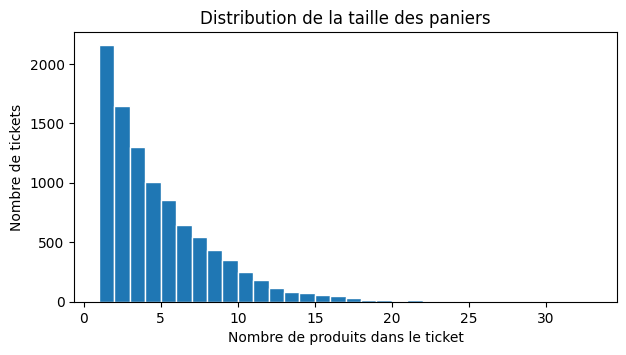

In [4]:
N = len(tickets)
tailles = pd.Series([len(t) for t in tickets])
produits_distincts = sorted({p for t in tickets for p in t})

print(f"Nombre de tickets                  : {N}")
print(f"Nombre de produits différents      : {len(produits_distincts)}")
print(f"Taille moyenne d'un panier         : {tailles.mean():.2f} produits")
print(f"Taille du plus grand panier        : {tailles.max()} produits")
print("\nLe plus grand panier :", tickets[int(tailles.idxmax())])

tailles.plot(kind="hist", bins=range(1, int(tailles.max()) + 2), color="tab:blue", edgecolor="white", figsize=(7, 3.5))
plt.title("Distribution de la taille des paniers")
plt.xlabel("Nombre de produits dans le ticket"); plt.ylabel("Nombre de tickets")
plt.show()

✍️ **Ma réponse A.1** : tickets = *(…)* ; produits différents = *(…)* ; taille moyenne = *(…)* ; plus grand panier = *(…)* produits.
La majorité des paniers sont *(petits : 1 à 5 produits)*, avec quelques très gros paniers.

## A.2 — Les produits stars
Le **support d'un produit** = part des tickets qui le contiennent.
*Pourquoi ?* Savoir quels produits sont populaires : ce sont eux qui domineront les motifs fréquents (et qui créeront le « piège » de C.2).

On compte chaque produit **une seule fois par ticket** (on utilise un `set`).

Top 10 des produits (support) :
whole milk          0.2555
other vegetables    0.1935
rolls/buns          0.1839
soda                0.1744
yogurt              0.1395
bottled water       0.1105
root vegetables     0.1090
tropical fruit      0.1049
shopping bags       0.0985
sausage             0.0940
dtype: float64


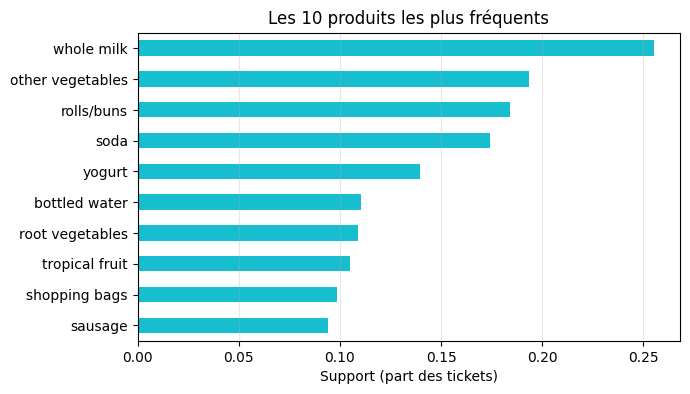

In [5]:
from collections import Counter

compteur = Counter(p for t in tickets for p in set(t))        # nombre de tickets contenant chaque produit
support_produit = (pd.Series(compteur) / N).sort_values(ascending=False)

print("Top 10 des produits (support) :")
print(support_produit.head(10).round(4))

support_produit.head(10).sort_values().plot(kind="barh", color="tab:cyan", figsize=(7, 4))
plt.title("Les 10 produits les plus fréquents")
plt.xlabel("Support (part des tickets)")
plt.grid(axis="x", alpha=0.3)
plt.show()

✍️ **Ma réponse A.2** : les 3 produits les plus fréquents sont *(whole milk : …, other vegetables : …, rolls/buns : …)*.
Le lait entier est présent dans *(…) %* des tickets : *(environ 1 ticket sur 4)*.

---
# PARTIE B — Les motifs fréquents · *6 points*

## B.1 — Apriori
### 1) Encodage booléen
`TransactionEncoder` transforme la liste de listes en **tableau booléen** : une ligne par ticket, une colonne par produit,
`True` si le produit est dans le ticket. *Pourquoi ?* C'est le format attendu par `apriori`.

In [6]:
te = TransactionEncoder()
tableau = te.fit(tickets).transform(tickets)                       # tableau numpy de booléens
df_bool = pd.DataFrame(tableau, columns=te.columns_)

print("Forme du tableau booléen (tickets × produits) :", df_bool.shape)
display(df_bool.iloc[:3, :8])

Forme du tableau booléen (tickets × produits) : (9835, 169)


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False


### 2) Apriori avec `min_support = 0,02`
**Apriori** cherche tous les **motifs fréquents** : ceux présents dans **au moins 2 % des tickets** (≈ 197 tickets).
*Pourquoi un seuil ?* Un motif rare (3 tickets sur 9 835) pourrait être dû au hasard ; on ne garde que ce qui est assez fréquent pour être fiable.
Principe d'Apriori : si un motif est rare, **tous les motifs qui le contiennent sont rares aussi** : on peut donc éliminer très vite
des milliers de combinaisons.

Nombre total de motifs fréquents : 122

Par taille (1, 2, 3 produits) :
taille
1    59
2    61
3     2
Name: count, dtype: int64


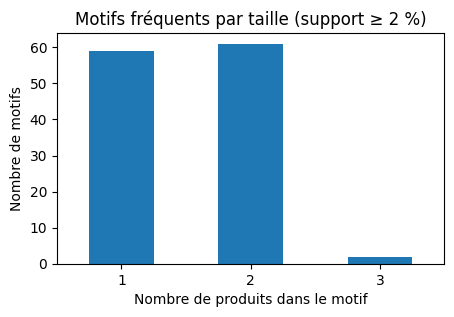

In [7]:
frequents = apriori(df_bool, min_support=0.02, use_colnames=True)
frequents["taille"] = frequents["itemsets"].apply(len)

print(f"Nombre total de motifs fréquents : {len(frequents)}")
par_taille = frequents["taille"].value_counts().sort_index()
print("\nPar taille (1, 2, 3 produits) :")
print(par_taille)

par_taille.plot(kind="bar", rot=0, color="tab:blue", figsize=(5, 3))
plt.title("Motifs fréquents par taille (support ≥ 2 %)")
plt.xlabel("Nombre de produits dans le motif"); plt.ylabel("Nombre de motifs")
plt.show()

✍️ **Ma réponse B.1** : *(…)* motifs fréquents au total : *(…)* de taille 1, *(…)* de taille 2, *(…)* de taille 3.
Plus les motifs sont grands, moins ils sont nombreux, car il est difficile que 3 produits précis se retrouvent souvent ensemble.

## B.2 — Les paires
On extrait les motifs de **taille 2** et on affiche les **8 au plus fort support**.
*Pourquoi ?* Ce sont les couples de produits les plus souvent achetés ensemble, point de départ des règles.

,paire,support
0,other vegetables + whole milk,0.0748
1,rolls/buns + whole milk,0.0566
2,whole milk + yogurt,0.0560
3,root vegetables + whole milk,0.0489
4,other vegetables + root vegetables,0.0474
5,other vegetables + yogurt,0.0434
6,other vegetables + rolls/buns,0.0426
7,tropical fruit + whole milk,0.0423


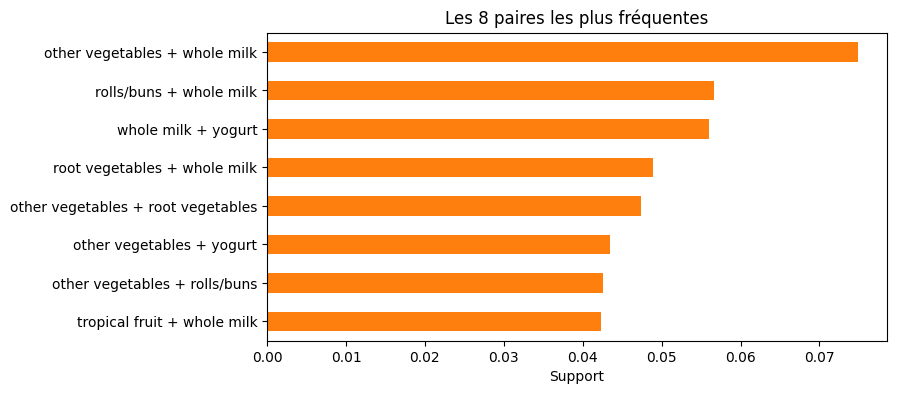

In [8]:
paires = frequents[frequents["taille"] == 2].copy()
paires["paire"] = paires["itemsets"].apply(lambda s: " + ".join(sorted(s)))
top_paires = paires.sort_values("support", ascending=False).head(8)[["paire", "support"]]
display(top_paires.round(4).reset_index(drop=True))

top_paires.sort_values("support").plot(x="paire", y="support", kind="barh", legend=False, color="tab:orange", figsize=(8, 4))
plt.title("Les 8 paires les plus fréquentes"); plt.xlabel("Support"); plt.ylabel("")
plt.show()

✍️ **Ma réponse B.2** : la paire la plus fréquente est *(…)* avec un support de *(…)*. On remarque que *(les paires les plus fréquentes
contiennent presque toutes un des produits stars : lait entier, autres légumes, petits pains)*.

## B.3 — À la main : yogurt ⇒ whole milk
**But** : recalculer **support, confiance et lift** avec de simples comptages `pandas`, pour comprendre les formules
avant de laisser `mlxtend` le faire.

On compte :
* `n_y` = tickets contenant le **yaourt** ;
* `n_l` = tickets contenant le **lait entier** ;
* `n_yl` = tickets contenant **les deux**.

Puis : **support = n_yl / N** ; **confiance = n_yl / n_y** ; **lift = confiance / (n_l / N)**.

In [9]:
X_, Y_ = "yogurt", "whole milk"

n_y = int(df_bool[X_].sum())
n_l = int(df_bool[Y_].sum())
n_yl = int((df_bool[X_] & df_bool[Y_]).sum())

support_xy = n_yl / N
confiance = n_yl / n_y
support_y = n_l / N
lift = confiance / support_y

print(f"Tickets avec yaourt        : {n_y}")
print(f"Tickets avec lait entier   : {n_l}")
print(f"Tickets avec les deux      : {n_yl}")
print()
print(f"Support   (yogurt ∪ whole milk) = {n_yl}/{N} = {support_xy:.4f}")
print(f"Confiance (yogurt ⇒ whole milk) = {n_yl}/{n_y} = {confiance:.4f}")
print(f"Support du lait entier          = {n_l}/{N} = {support_y:.4f}")
print(f"Lift = {confiance:.4f} / {support_y:.4f} = {lift:.3f}")

Tickets avec yaourt        : 1372
Tickets avec lait entier   : 2513
Tickets avec les deux      : 551

Support   (yogurt ∪ whole milk) = 551/9835 = 0.0560
Confiance (yogurt ⇒ whole milk) = 551/1372 = 0.4016
Support du lait entier          = 2513/9835 = 0.2555
Lift = 0.4016 / 0.2555 = 1.572


✍️ **Ma réponse B.3** : n_y = *(…)*, n_l = *(…)*, n_yl = *(…)* ; support = *(…)*, confiance = *(…)*, lift = *(…)*.
**Interprétation du lift** : parmi les acheteurs de yaourt, *(…) %* achètent aussi du lait, contre *(…) %* pour l'ensemble des clients.
Le lift de *(…)* signifie que le yaourt rend l'achat de lait *(…) fois plus probable* que la normale : il y a *(attraction positive mais modérée / forte)*.
(Un lift de 1 voudrait dire « indépendance » : le yaourt n'aurait aucune influence sur l'achat de lait.)

---
# PARTIE C — Les règles · *5 points*

## C.1 — Générer les règles
`association_rules` transforme les motifs fréquents en **règles X ⇒ Y** et calcule leurs mesures. On garde celles de
**confiance ≥ 0,3** (au moins 30 % des acheteurs de X achètent aussi Y).

*Pourquoi la confiance comme filtre ?* Un motif fréquent ne suffit pas : il faut que la règle soit **assez fiable** pour être utile.

In [10]:
def generer_regles(motifs, nb_tickets, metric="confidence", min_threshold=0.3):
    """Appelle association_rules en restant compatible avec les différentes versions de mlxtend."""
    try:
        return association_rules(motifs, metric=metric, min_threshold=min_threshold)
    except TypeError:                                   # versions récentes : argument num_itemsets obligatoire
        return association_rules(motifs, num_itemsets=nb_tickets, metric=metric, min_threshold=min_threshold)

regles = generer_regles(frequents.drop(columns="taille"), N, "confidence", 0.3)
print(f"Nombre de règles (confiance ≥ 0,3) : {len(regles)}")

def formater(r):
    """Tableau lisible : antécédent, conséquent, support, confiance, lift."""
    out = pd.DataFrame({
        "antécédent": r["antecedents"].apply(lambda s: " + ".join(sorted(s))),
        "conséquent": r["consequents"].apply(lambda s: " + ".join(sorted(s))),
        "support": r["support"], "confiance": r["confidence"], "lift": r["lift"]})
    return out.round(3)

print("\nLes 8 règles au plus fort lift :")
display(formater(regles).sort_values("lift", ascending=False).head(8).reset_index(drop=True))

Nombre de règles (confiance ≥ 0,3) : 37

Les 8 règles au plus fort lift :


,antécédent,conséquent,support,confiance,lift
0,other vegetables + whole milk,root vegetables,0.023,0.310,2.842
1,root vegetables + whole milk,other vegetables,0.023,0.474,2.450
2,root vegetables,other vegetables,0.047,0.435,2.247
3,whipped/sour cream,other vegetables,0.029,0.403,2.082
4,whole milk + yogurt,other vegetables,0.022,0.397,2.054
5,other vegetables + yogurt,whole milk,0.022,0.513,2.007
6,butter,whole milk,0.028,0.497,1.946
7,pork,other vegetables,0.022,0.376,1.941


In [11]:
# Contrôle : la règle yogurt ⇒ whole milk calculée à la main en B.3 doit se retrouver ici
mask = (regles["antecedents"] == frozenset({"yogurt"})) & (regles["consequents"] == frozenset({"whole milk"}))
display(formater(regles[mask]))
print(f"À la main (B.3) : support = {support_xy:.3f} | confiance = {confiance:.3f} | lift = {lift:.3f}")

,antécédent,conséquent,support,confiance,lift
31,yogurt,whole milk,0.056,0.402,1.572


À la main (B.3) : support = 0.056 | confiance = 0.402 | lift = 1.572


✍️ **Ma réponse C.1** : *(…)* règles ; les 8 règles au plus fort lift sont *(recopier le tableau)*.
Les meilleures règles associent *(des légumes racines, des fruits, des produits laitiers…)*, avec des lifts de *(…)*.
Les valeurs de la règle yogurt ⇒ whole milk correspondent *(exactement)* au calcul à la main de B.3.

## C.2 — Le piège du produit populaire
Beaucoup de règles se terminent par **whole milk**. Est-ce une vraie association ou un effet de popularité ?

* Le lait entier est dans environ **1 ticket sur 4**. Toute règle « n'importe quoi ⇒ lait entier » aura donc **mécaniquement une confiance
  d'au moins ~25 %**, même si le produit de gauche n'a **aucune influence** sur le lait.
* La **confiance ne tient pas compte de la popularité du conséquent** ; le **lift**, si (il divise par supp(Y)).

Nombre de règles ayant whole milk pour conséquent : 24 sur 37 (65%)
Support du lait entier (base de comparaison) : 0.256

Règles vers le lait entier, triées par confiance :


,antécédent,conséquent,support,confiance,lift
0,other vegetables + yogurt,whole milk,0.022,0.513,2.007
1,butter,whole milk,0.028,0.497,1.946
2,curd,whole milk,0.026,0.490,1.919
3,other vegetables + root vegetables,whole milk,0.023,0.489,1.915
4,domestic eggs,whole milk,0.030,0.473,1.850
5,whipped/sour cream,whole milk,0.032,0.450,1.760
6,root vegetables,whole milk,0.049,0.449,1.756
7,frozen vegetables,whole milk,0.020,0.425,1.663


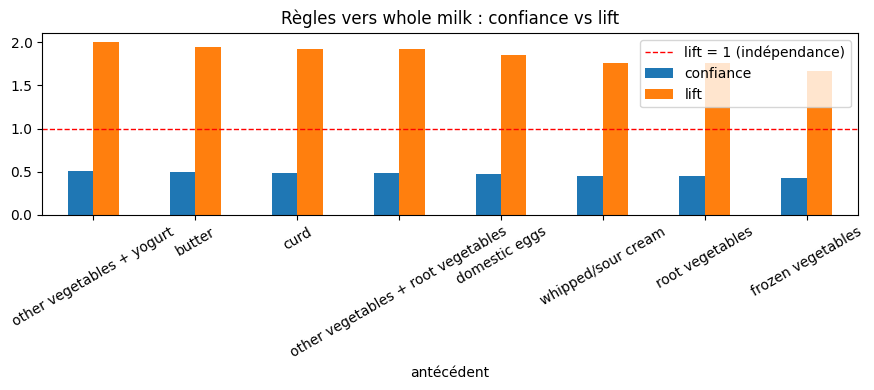

In [12]:
rl = regles[regles["consequents"] == frozenset({"whole milk"})]
print(f"Nombre de règles ayant whole milk pour conséquent : {len(rl)} sur {len(regles)} ({len(rl) / len(regles):.0%})")
print(f"Support du lait entier (base de comparaison) : {support_produit['whole milk']:.3f}")

print("\nRègles vers le lait entier, triées par confiance :")
display(formater(rl).sort_values("confiance", ascending=False).head(8).reset_index(drop=True))

# Comparaison : confiance "flatteuse" vs lift "honnête"
tab = formater(rl).sort_values("confiance", ascending=False).head(8)
ax = tab.set_index("antécédent")[["confiance", "lift"]].plot(kind="bar", figsize=(9, 4), rot=30)
ax.axhline(1, color="red", ls="--", lw=1, label="lift = 1 (indépendance)")
ax.set_title("Règles vers whole milk : confiance vs lift"); ax.legend()
plt.tight_layout(); plt.show()

✍️ **Ma réponse C.2** :
* Nombre de règles avec **whole milk** en conséquent : *(…)* sur *(…)*.
* **Pourquoi si souvent ?** Parce que c'est le produit le plus populaire (support ≈ *(…)*) : presque n'importe quel panier a de bonnes chances d'en contenir.
* **Quel indicateur permet de ne pas se laisser tromper ?** Le **lift** : il compare la confiance à la popularité du conséquent. Un lift proche de 1 (par ex. 1,0 à 1,3)
  montre que la règle n'apporte presque rien par rapport au hasard, malgré une confiance qui semble élevée.

## C.3 — Choisir
On ne garde que les règles **vraiment intéressantes** : **lift > 1,5** (association nette) **et confiance ≥ 0,4** (règle assez fiable).
Puis on propose au directeur du magasin **deux actions concrètes**.

In [13]:
fortes = regles[(regles["lift"] > 1.5) & (regles["confidence"] >= 0.4)]
print(f"Règles retenues (lift > 1,5 et confiance ≥ 0,4) : {len(fortes)}")
display(formater(fortes).sort_values("lift", ascending=False).reset_index(drop=True))

Règles retenues (lift > 1,5 et confiance ≥ 0,4) : 15


,antécédent,conséquent,support,confiance,lift
0,root vegetables + whole milk,other vegetables,0.023,0.474,2.450
1,root vegetables,other vegetables,0.047,0.435,2.247
2,whipped/sour cream,other vegetables,0.029,0.403,2.082
3,other vegetables + yogurt,whole milk,0.022,0.513,2.007
4,butter,whole milk,0.028,0.497,1.946
5,curd,whole milk,0.026,0.490,1.919
6,other vegetables + root vegetables,whole milk,0.023,0.489,1.915
7,domestic eggs,whole milk,0.030,0.473,1.850
8,whipped/sour cream,whole milk,0.032,0.450,1.760
9,root vegetables,whole milk,0.049,0.449,1.756


✍️ **Ma réponse C.3** — *deux actions concrètes à proposer au directeur* (à adapter à VOS règles) :

1. **Placement en rayon** : *(ex. placer les légumes racines à côté des autres légumes / des fruits, puisque « fruits + légumes racines ⇒ autres légumes » a un lift de … et une confiance de …)*.
2. **Promotion croisée** : *(ex. proposer une réduction sur le lait pour l'achat de yaourt + fromage blanc, ou un coupon « légumes » à la caisse pour les acheteurs de fruits et légumes racines)*.

Justifier chaque action avec **une règle précise** (antécédent ⇒ conséquent, confiance, lift) et expliquer en quoi elle augmente le panier moyen.

---
# PARTIE D — Le même travail dans Orange · *3 points*
**But** : retrouver les mêmes motifs et les mêmes règles avec un outil visuel, et comparer.

*Préparation* : menu **Options → Add-ons**, cocher **Associate**, puis relancer Orange.

### Workflow Orange à construire
`File (panier.basket) → Frequent Itemsets → Association Rules → Data Table`

| Étape | Widget | Réglages et pourquoi |
|---|---|---|
| 1 | **File** | Ouvrir **`panier.basket`** (le même fichier au format « panier » d'Orange) |
| 2 | **Frequent Itemsets** | **Support minimal 2 %**, puis **Find Itemsets**. Comparer le **nombre de motifs** avec B.1 |
| 3 | **Association Rules** | **Support minimal 2 %**, **confiance minimale 30 %**. **Trier par lift** |
| 4 | **Data Table** | Lire les règles et les **comparer à celles de Python** : sont-elles identiques ? |

👉 Enregistrer en **`.ows`** (Fichier → Enregistrer).

### Vérification / aide à la comparaison en Python
Cette cellule résume les nombres à comparer avec Orange et exporte les règles Python en CSV.
(De petites différences sont possibles : Orange et mlxtend n'arrondissent pas toujours les seuils de la même manière,
et le comptage de certains motifs de taille 1 peut varier selon le widget.)

In [14]:
resume = pd.DataFrame({
    "Python (mlxtend)": {
        "motifs fréquents (support ≥ 2 %)": len(frequents),
        "dont taille 1": int((frequents["taille"] == 1).sum()),
        "dont taille 2": int((frequents["taille"] == 2).sum()),
        "dont taille 3": int((frequents["taille"] == 3).sum()),
        "règles (support ≥ 2 %, confiance ≥ 30 %)": len(regles)},
    "Orange (à remplir)": "",
})
display(resume)

formater(regles).sort_values("lift", ascending=False).to_csv("regles_python.csv", index=False)
print("Règles Python enregistrées dans regles_python.csv (pour comparer ligne à ligne avec Orange).")

,Python (mlxtend),Orange (à remplir)
motifs fréquents (support ≥ 2 %),122,
dont taille 1,59,
dont taille 2,61,
dont taille 3,2,
"règles (support ≥ 2 %, confiance ≥ 30 %)",37,


Règles Python enregistrées dans regles_python.csv (pour comparer ligne à ligne avec Orange).


✍️ **Ma réponse D** *(valeurs lues dans Orange)* :

| | Python | Orange |
|---|---|---|
| Nombre de motifs fréquents | | |
| Nombre de règles | | |
| Règle au plus fort lift | | |

* Les règles d'Orange sont-elles **identiques** à celles de Python ? *(compter combien de règles du top 8 se retrouvent dans les deux ; expliquer les écarts éventuels : arrondi des seuils, comptage des motifs de taille 1, présentation des règles)*.
* Avantage d'Orange : *(visuel, rapide, sans code)* ; avantage de Python : *(flexible, reproductible, permet de coder `recommander`)*.

---
# PARTIE E — De la règle à la recommandation · *3 points*
## E.1 — Recommander
**But** : utiliser les règles pour **conseiller des produits** à un client dont on connaît le panier en cours.

La fonction `recommander(panier, regles, n=3)` :
1. garde les règles dont l'**antécédent est inclus dans le panier** (le client a déjà tous les produits de gauche) ;
2. ne retient que les produits **conséquents absents du panier** (inutile de conseiller ce qu'il a déjà) ;
3. les **classe par lift décroissant** et renvoie les **n meilleurs**.

*Pourquoi le lift et non la confiance ?* Pour ne pas recommander systématiquement les produits populaires (voir C.2).

In [15]:
def recommander(panier, regles, n=3):
    """Renvoie les n produits conseillés (liste de tuples : produit, lift, confiance)."""
    panier = set(panier)
    meilleurs = {}                                             # produit -> (lift, confiance) de sa meilleure règle
    for _, r in regles.iterrows():
        antecedent, consequent = r["antecedents"], r["consequents"]
        if antecedent <= panier and consequent.isdisjoint(panier):     # antécédent inclus, conséquent absent du panier
            for produit in consequent:
                if produit not in meilleurs or r["lift"] > meilleurs[produit][0]:
                    meilleurs[produit] = (r["lift"], r["confidence"])
    classement = sorted(meilleurs.items(), key=lambda kv: kv[1][0], reverse=True)    # tri par lift décroissant
    return [(p, round(l, 3), round(c, 3)) for p, (l, c) in classement[:n]]

for panier_test in (["yogurt", "tropical fruit"], ["root vegetables"]):
    print(f"Panier : {panier_test}")
    reco = recommander(panier_test, regles, n=3)
    if reco:
        for produit, l, c in reco:
            print(f"   -> {produit:<22} lift = {l} | confiance = {c}")
    else:
        print("   -> aucune recommandation (aucune règle ne s'applique)")
    print()

Panier : ['yogurt', 'tropical fruit']
   -> other vegetables       lift = 1.768 | confiance = 0.342
   -> whole milk             lift = 1.578 | confiance = 0.403

Panier : ['root vegetables']
   -> other vegetables       lift = 2.247 | confiance = 0.435
   -> whole milk             lift = 1.756 | confiance = 0.449



✍️ **Ma réponse E.1** :
* Pour `["yogurt", "tropical fruit"]` la fonction conseille *(…)*, car *(les règles dont l'antécédent est inclus dans ce panier ont pour conséquents …)*.
* Pour `["root vegetables"]` elle conseille *(…)*.
* **Limites** : la fonction ne s'applique qu'aux règles générées avec nos seuils (support ≥ 2 %, confiance ≥ 30 %) : un panier inhabituel peut ne recevoir
  aucune recommandation ; elle ne tient pas compte du prix, de la marge, ni de l'ordre des achats.

---
#  Conclusion générale
* **Format panier** : chaque ticket est un ensemble de produits ; on le transforme en tableau booléen pour l'analyse.
* **Apriori** trouve les motifs fréquents (**support**) ; **association_rules** en tire des règles évaluées par la **confiance** et le **lift**.
* **Le piège du produit populaire** : un produit très fréquent (lait entier) apparaît dans beaucoup de règles uniquement par effet de masse ; le **lift** permet de séparer les vraies associations du hasard.
* **De la règle à l'action** : on filtre (lift > 1,5, confiance ≥ 0,4), puis on traduit en actions concrètes (rayon, promotion croisée) et en **recommandation**.
* **Limites** : corrélation ≠ causalité (acheter A n'*entraîne* pas l'achat de B), seuils choisis à la main, produits regroupés en catégories.

